# 01 — Análise do Consumo Residencial
## Projeto Citizen Assist AI

**Instituição:** FIAP  
**Componente curricular:** Soluções em Energias Renováveis e Sustentáveis  
**Projeto:** Citizen Assist AI  
**Etapa:** Integração dos resultados energéticos, assistente conversacional e testes  
**Localidade de referência:** São Paulo — SP, Brasil
**Distribuidora de referência:** Enel Distribuição São Paulo  
**Perfil residencial de estudo:** família simulada de quatro moradores

---

## Objetivo

Este notebook reúne a preparação e a análise de dados necessários para caracterizar o consumo residencial e estabelecer uma referência para a comparação de alternativas de eficiência energética e geração renovável.

A análise combina:

- **Dados oficiais:** informações tarifárias da ANEEL e estatísticas de consumo da EPE.
- **Dados simulados:** perfil de moradores e equipamentos de uma residência hipotética.
- **Resultados calculados:** indicadores derivados dos dados e das premissas explicitadas neste documento.

> **Limite de interpretação:** os dados estaduais da EPE são agregados e não representam o consumo medido de uma residência específica. O perfil doméstico será calculado separadamente a partir de premissas simuladas.

### Público e necessidade energética

O público de referência deste estudo são moradores de residências urbanas em São Paulo — SP, utilizando como cenário de análise uma família hipotética de quatro pessoas.

A necessidade identificada é compreender o consumo doméstico de energia elétrica e avaliar alternativas que possam reduzir os gastos e o desperdício energético, considerando também a possibilidade de adoção de fontes renováveis.

O Citizen Assist AI deverá utilizar essas informações para oferecer orientações acessíveis, fundamentadas em dados e acompanhadas das respectivas limitações.

## 1. Organização do ambiente

Nesta seção são importadas as bibliotecas e definidos os diretórios utilizados pelo projeto.

A pasta `data/raw` preserva os arquivos originais; `data/processed` recebe os arquivos tratados; e `references` armazena informações de referência. No Google Colab, o armazenamento em `/content` é temporário e deve ser copiado para um local persistente ao final da sessão.

In [96]:
%pip install -q pandas numpy matplotlib pyarrow openpyxl

In [97]:
import json
import shutil
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda valor: f"{valor:,.3f}")

# Diretório de trabalho.
# No Colab, /content é temporário. Em Jupyter local, altere BASE_DIR
# para uma pasta de projeto adequada.
BASE_DIR = Path("/content/GS_SERS")

RAW_DIR = BASE_DIR / "data" / "raw"
PROCESSED_DIR = BASE_DIR / "data" / "processed"
REFERENCES_DIR = BASE_DIR / "references"

for diretorio in [RAW_DIR, PROCESSED_DIR, REFERENCES_DIR]:
    diretorio.mkdir(parents=True, exist_ok=True)

print("Diretório do projeto:", BASE_DIR)

Diretório do projeto: /content/GS_SERS


### 1.1. Parâmetros do estudo

Os parâmetros abaixo definem o recorte geográfico e o perfil residencial de referência. O perfil é uma hipótese de trabalho, não uma descrição de uma família real.

In [98]:
LOCALIDADE = "São Paulo - SP"
UF = "SP"
DISTRIBUIDORA = "Enel Distribuição São Paulo"

PERFIL_RESIDENCIAL = {
    "tipo": "Família",
    "moradores": 4,
    "localidade": LOCALIDADE,
    "origem": "Simulado",
    "periodo_referencia": "30 dias"
}

display(pd.DataFrame([PERFIL_RESIDENCIAL]))

,tipo,moradores,localidade,origem,periodo_referencia
0,Família,4,São Paulo - SP,Simulado,30 dias


### 1.2. Registro das fontes

O registro abaixo documenta as fontes previstas nesta etapa. A fonte do INPE está registrada para a etapa futura de potencial solar; ela ainda não é processada neste notebook.

In [99]:
fontes = {
    "ANEEL": {
        "instituicao": "Agência Nacional de Energia Elétrica",
        "url": "https://dadosabertos.aneel.gov.br/",
        "uso": "Tarifas de aplicação das distribuidoras",
        "tipo": "Oficial"
    },
    "EPE": {
        "instituicao": "Empresa de Pesquisa Energética",
        "url": "https://www.epe.gov.br/pt/publicacoes-dados-abertos/dados-abertos/dados-do-consumo-mensal-de-energia-eletrica",
        "dicionario": "https://www.epe.gov.br/sites-pt/publicacoes-dados-abertos/dados-abertos/Documents/Consumo-Mensal-Dicionario-de-Dados.pdf",
        "uso": "Consumo mensal por classe e unidade da federação",
        "tipo": "Oficial"
    },
    "INPE": {
        "instituicao": "Instituto Nacional de Pesquisas Espaciais",
        "url": "https://labren.ccst.inpe.br/atlas_2017.html",
        "uso": "Referência futura para irradiação solar",
        "tipo": "Oficial"
    }
}

with open(REFERENCES_DIR / "fontes.json", "w", encoding="utf-8") as arquivo:
    json.dump(fontes, arquivo, ensure_ascii=False, indent=4)

print("Registro de fontes salvo em:", REFERENCES_DIR / "fontes.json")

Registro de fontes salvo em: /content/GS_SERS/references/fontes.json


## 2. Dados tarifários — ANEEL

A ANEEL disponibiliza dados de tarifas homologadas pelas distribuidoras de energia elétrica.

Para a residência de referência, interessa a tarifa do subgrupo **B1 — Residencial**, modalidade convencional e base tarifária de aplicação. Os componentes de interesse são:

- **TUSD:** Tarifa de Uso do Sistema de Distribuição.
- **TE:** Tarifa de Energia.

Os valores do conjunto utilizado são expressos em R$/MWh. Para expressá-los em R$/kWh, divide-se por 1.000.

**Atenção:** TUSD + TE não equivale necessariamente ao valor final da conta. Tributos, bandeiras tarifárias, contribuição de iluminação pública e outras parcelas podem alterar o total faturado. A análise tarifária deve respeitar a vigência do registro.

### 2.1. Disponibilizar o arquivo oficial

Utilize o arquivo Parquet baixado da página oficial da ANEEL. A célula aceita upload no Google Colab. Em Jupyter local, coloque o arquivo na pasta `data/raw` com o nome `aneel_tarifas_original.parquet`.

In [100]:
ARQUIVO_ANEEL = RAW_DIR / "aneel_tarifas_original.parquet"

if not ARQUIVO_ANEEL.exists():
    try:
        from google.colab import files

        print("Envie o arquivo Parquet de tarifas da ANEEL.")
        enviados = files.upload()
        candidatos = [
            Path(nome) for nome in enviados
            if nome.lower().endswith(".parquet")
        ]

        if not candidatos:
            raise FileNotFoundError("Nenhum arquivo Parquet foi enviado.")

        shutil.copy2(candidatos[0], ARQUIVO_ANEEL)

    except ImportError:
        raise FileNotFoundError(
            f"Coloque o arquivo Parquet da ANEEL em: {ARQUIVO_ANEEL}"
        )

df_aneel = pd.read_parquet(ARQUIVO_ANEEL)

print("Arquivo:", ARQUIVO_ANEEL)
print("Dimensões:", df_aneel.shape)
display(df_aneel.head())

Arquivo: /content/GS_SERS/data/raw/aneel_tarifas_original.parquet
Dimensões: (657709, 17)


,DatGeracaoConjuntoDados,DscREH,SigAgente,NumCNPJDistribuidora,DatInicioVigencia,DatFimVigencia,DscBaseTarifaria,DscSubGrupo,DscModalidadeTarifaria,DscClasse,DscSubClasse,DscDetalhe,NomPostoTarifario,DscUnidadeTerciaria,SigAgenteAcessante,VlrTUSD,VlrTE
0,2026-11-12,"RESOLUÇÃO HOMOLOGATÓRIA Nº 0.937, DE 2 DE FEVE...",CPFL JAGUARI,53859112000169,2010-02-03,2011-02-02,Tarifa de Aplicação,A2,Azul,Não se aplica,Não se aplica,APE,Fora ponta,kW,Não se aplica,1.850,0.000
1,2026-11-12,"RESOLUÇÃO HOMOLOGATÓRIA Nº 0.937, DE 2 DE FEVE...",CPFL JAGUARI,53859112000169,2010-02-03,2011-02-02,Base Econômica,A2,Azul,Não se aplica,Não se aplica,APE,Fora ponta,kW,Não se aplica,1.850,0.000
2,2026-11-12,"RESOLUÇÃO HOMOLOGATÓRIA Nº 0.937, DE 2 DE FEVE...",CPFL JAGUARI,53859112000169,2010-02-03,2011-02-02,Base Econômica,A2,Azul,Não se aplica,Não se aplica,APE,Fora ponta,kW,Não se aplica,1.850,0.000
3,2026-11-12,"RESOLUÇÃO HOMOLOGATÓRIA Nº 0.937, DE 2 DE FEVE...",CPFL JAGUARI,53859112000169,2010-02-03,2011-02-02,Tarifa de Aplicação,A2,Azul,Não se aplica,Não se aplica,APE,Fora ponta,kW,Não se aplica,1.850,0.000
4,2026-11-12,"RESOLUÇÃO HOMOLOGATÓRIA Nº 0.937, DE 2 DE FEVE...",CPFL JAGUARI,53859112000169,2010-02-03,2011-02-02,Base Econômica,A2,Azul,Não se aplica,Não se aplica,APE,Ponta,kW,Não se aplica,19.050,0.000


### 2.2. Validar a estrutura e identificar a distribuidora

Esta etapa verifica se os campos necessários existem e lista os agentes cujo nome contém “ENEL”. A identificação do agente e o filtro final da tarifa devem ser conferidos com os valores efetivamente presentes no arquivo.

In [101]:
colunas_esperadas_aneel = [
    "SigAgente",
    "DatInicioVigencia",
    "DatFimVigencia",
    "DscBaseTarifaria",
    "DscSubGrupo",
    "DscModalidadeTarifaria",
    "DscClasse",
    "DscSubClasse",
    "VlrTUSD",
    "VlrTE"
]

colunas_ausentes = [
    coluna for coluna in colunas_esperadas_aneel
    if coluna not in df_aneel.columns
]

if colunas_ausentes:
    raise KeyError(f"Campos esperados ausentes: {colunas_ausentes}")

print("Todos os campos esperados foram encontrados.")
display(df_aneel.dtypes.to_frame("tipo"))

Todos os campos esperados foram encontrados.


,tipo
DatGeracaoConjuntoDados,object
DscREH,object
SigAgente,object
NumCNPJDistribuidora,int64
DatInicioVigencia,object
DatFimVigencia,object
DscBaseTarifaria,object
DscSubGrupo,object
DscModalidadeTarifaria,object
DscClasse,object


In [102]:
termos_busca = (
    "SÃO PAULO|SAO PAULO|PIRATININGA|"
    "ELETROPAULO|ENEL"
)

agentes_relevantes = (
    df_aneel.loc[
        df_aneel["SigAgente"].astype(str).str.contains(
            termos_busca,
            case=False,
            na=False,
            regex=True
        ),
        "SigAgente"
    ]
    .drop_duplicates()
    .sort_values()
)

display(agentes_relevantes.to_frame("Agentes identificados"))

,Agentes identificados
9096,ELETROPAULO
4440,ENEL CE
1192,ENEL RJ


### 2.3. Inspeção dos registros residenciais

Antes de selecionar uma tarifa específica, inspecione as categorias disponíveis. Não aplique filtros com rótulos presumidos: os valores textuais podem variar conforme a versão do conjunto de dados.

In [103]:
for coluna in [
    "DscBaseTarifaria",
    "DscSubGrupo",
    "DscModalidadeTarifaria",
    "DscClasse",
    "DscSubClasse"
]:
    print(f"\n{coluna}:")
    display(
        df_aneel[coluna]
        .dropna()
        .astype(str)
        .value_counts()
        .head(20)
        .to_frame("Quantidade")
    )


DscBaseTarifaria:


,Quantidade
DscBaseTarifaria,
Tarifa de Aplicação,329831
Base Econômica,327878



DscSubGrupo:


,Quantidade
DscSubGrupo,
A4,170002
B2,142417
B1,83285
A2,68120
A3a,49538
B3,47557
A3,37954
B4,21896
A1,15528



DscModalidadeTarifaria:


,Quantidade
DscModalidadeTarifaria,
Azul,165352
Branca,145151
Convencional,114548
Verde,75308
Geração,62412
Convencional pré-pagamento,53696
Distribuição,38054
Energia suprimento,1032
Convencional ABRACE,656



DscClasse:


,Quantidade
DscClasse,
Não se aplica,408899
Rural,143625
Residencial,83289
Iluminação pública,21896



DscSubClasse:


,Quantidade
DscSubClasse,
Não se aplica,455236
Cooperativa de eletrificação rural,49902
Residencial,47491
Serviço público de irrigação rural,47442
Baixa Renda,18478
Iluminação pública – B4a,10948
Iluminação pública – B4b,10948
Residencial Tarifa Social – faixa 01,5544
Residencial Tarifa Social – faixa 02,5544


### 2.4. Preparar uma visão de tarifas Enel B1

A célula abaixo aplica apenas os filtros de agente e subgrupo B1, preservando as demais categorias para inspeção. A seleção da vigência e das descrições de classe/modalidade deve ser confirmada na saída anterior antes de usar os valores em uma simulação de custo.

In [104]:
df_aneel["DatInicioVigencia"] = pd.to_datetime(
    df_aneel["DatInicioVigencia"], errors="coerce"
)
df_aneel["DatFimVigencia"] = pd.to_datetime(
    df_aneel["DatFimVigencia"], errors="coerce"
)

df_aneel_enel_b1 = df_aneel[
df_aneel["SigAgente"].astype(str).str.strip().str.upper().eq(
    "ELETROPAULO"
)

    & df_aneel["DscSubGrupo"].astype(str).str.contains(
        "B1", case=False, na=False
    )
].copy()

print("Registros Enel / B1:", len(df_aneel_enel_b1))
display(
    df_aneel_enel_b1[
        [
            "SigAgente", "DatInicioVigencia", "DatFimVigencia",
            "DscBaseTarifaria", "DscSubGrupo",
            "DscModalidadeTarifaria", "DscClasse",
            "DscSubClasse", "VlrTUSD", "VlrTE"
        ]
    ].sort_values("DatInicioVigencia", ascending=False).head(20)
)

Registros Enel / B1: 874


,SigAgente,DatInicioVigencia,DatFimVigencia,DscBaseTarifaria,DscSubGrupo,DscModalidadeTarifaria,DscClasse,DscSubClasse,VlrTUSD,VlrTE
629158,ELETROPAULO,2026-07-04,2027-07-03,Tarifa de Aplicação,B1,Convencional pré-pagamento,Residencial,Residencial Tarifa Social – faixa 02,306.310,37.190
629098,ELETROPAULO,2026-07-04,2027-07-03,Tarifa de Aplicação,B1,Convencional,Residencial,Residencial Desconto Social – faixa 01,316.880,316.780
629070,ELETROPAULO,2026-07-04,2027-07-03,Base Econômica,B1,Convencional,Residencial,Residencial,453.320,308.110
629071,ELETROPAULO,2026-07-04,2027-07-03,Tarifa de Aplicação,B1,Branca,Residencial,Residencial,997.850,482.450
629072,ELETROPAULO,2026-07-04,2027-07-03,Tarifa de Aplicação,B1,Branca,Residencial,Residencial,997.850,482.450
629073,ELETROPAULO,2026-07-04,2027-07-03,Base Econômica,B1,Branca,Residencial,Residencial,980.180,462.080
629074,ELETROPAULO,2026-07-04,2027-07-03,Base Econômica,B1,Branca,Residencial,Residencial,980.180,462.080
629075,ELETROPAULO,2026-07-04,2027-07-03,Base Econômica,B1,Branca,Residencial,Residencial,347.950,47.300
629076,ELETROPAULO,2026-07-04,2027-07-03,Base Econômica,B1,Branca,Residencial,Residencial,347.950,47.300
629077,ELETROPAULO,2026-07-04,2027-07-03,Tarifa de Aplicação,B1,Branca,Residencial,Residencial,367.330,37.360


In [105]:
diagnostico_tarifas = (
    df_aneel_enel_b1
    .groupby(
        [
            "DscBaseTarifaria",
            "DscModalidadeTarifaria",
            "DscClasse",
            "DscSubClasse"
        ],
        dropna=False
    )
    .size()
    .reset_index(name="Quantidade de registros")
)

display(diagnostico_tarifas)

,DscBaseTarifaria,DscModalidadeTarifaria,DscClasse,DscSubClasse,Quantidade de registros
0,Base Econômica,Branca,Residencial,Residencial,166
1,Base Econômica,Convencional,Residencial,Baixa Renda,56
2,Base Econômica,Convencional,Residencial,Residencial,56
3,Base Econômica,Convencional,Residencial,Residencial Desconto Social – faixa 01,8
4,Base Econômica,Convencional,Residencial,Residencial Desconto Social – faixa 02,8
5,Base Econômica,Convencional,Residencial,Residencial Tarifa Social – faixa 01,12
6,Base Econômica,Convencional,Residencial,Residencial Tarifa Social – faixa 02,12
7,Base Econômica,Convencional pré-pagamento,Residencial,Baixa Renda,40
8,Base Econômica,Convencional pré-pagamento,Residencial,Residencial,40
9,Base Econômica,Convencional pré-pagamento,Residencial,Residencial Desconto Social – faixa 01,8


In [106]:
df_tarifa_residencial = df_aneel_enel_b1.loc[
    (df_aneel_enel_b1["DscBaseTarifaria"] == "Tarifa de Aplicação")
    &
    (df_aneel_enel_b1["DscModalidadeTarifaria"] == "Convencional")
    &
    (df_aneel_enel_b1["DscClasse"] == "Residencial")
    &
    (df_aneel_enel_b1["DscSubClasse"] == "Residencial")
].copy()

df_tarifa_residencial = df_tarifa_residencial.sort_values(
    "DatInicioVigencia"
)

print(
    "Registros residenciais convencionais:",
    len(df_tarifa_residencial)
)

display(
    df_tarifa_residencial[
        [
            "DatInicioVigencia",
            "DatFimVigencia",
            "DscDetalhe",
            "DscUnidadeTerciaria",
            "VlrTUSD",
            "VlrTE"
        ]
    ].tail(10)
)

Registros residenciais convencionais: 56


,DatInicioVigencia,DatFimVigencia,DscDetalhe,DscUnidadeTerciaria,VlrTUSD,VlrTE
533936,2025-07-04,2025-12-31,SCEE,MWh,432.440,36.980
533938,2025-07-04,2025-12-31,SCEE,MWh,432.440,36.980
598834,2026-01-01,2026-07-03,SCEE,MWh,432.440,36.980
598811,2026-01-01,2026-07-03,Não se aplica,MWh,432.440,292.740
598814,2026-01-01,2026-07-03,Não se aplica,MWh,432.440,292.740
598832,2026-01-01,2026-07-03,SCEE,MWh,432.440,36.980
629065,2026-07-04,2027-07-03,Não se aplica,MWh,472.420,316.960
629089,2026-07-04,2027-07-03,SCEE,MWh,472.420,37.360
629063,2026-07-04,2027-07-03,Não se aplica,MWh,472.420,316.960
629090,2026-07-04,2027-07-03,SCEE,MWh,472.420,37.360


In [107]:
registros_atuais = df_tarifa_residencial.loc[
    (df_tarifa_residencial["DatInicioVigencia"] == "2026-07-04")
    &
    (df_tarifa_residencial["DatFimVigencia"] == "2027-07-03")
].copy()

duplicatas_exatas = registros_atuais.loc[
    registros_atuais.duplicated(keep=False)
].sort_values(["DscDetalhe", "VlrTE"])

print("Registros na vigência atual:", len(registros_atuais))

print(
    "Linhas duplicadas além da primeira:",
    int(registros_atuais.duplicated().sum())
)

print(
    "Linhas pertencentes a grupos duplicados:",
    len(duplicatas_exatas)
)

display(duplicatas_exatas)

Registros na vigência atual: 4
Linhas duplicadas além da primeira: 2
Linhas pertencentes a grupos duplicados: 4


,DatGeracaoConjuntoDados,DscREH,SigAgente,NumCNPJDistribuidora,DatInicioVigencia,DatFimVigencia,DscBaseTarifaria,DscSubGrupo,DscModalidadeTarifaria,DscClasse,DscSubClasse,DscDetalhe,NomPostoTarifario,DscUnidadeTerciaria,SigAgenteAcessante,VlrTUSD,VlrTE
629065,2026-11-12,"RESOLUÇÃO HOMOLOGATÓRIA Nº 3.596, DE 3 DE JULH...",ELETROPAULO,61695227000193,2026-07-04,2027-07-03,Tarifa de Aplicação,B1,Convencional,Residencial,Residencial,Não se aplica,Não se aplica,MWh,Não se aplica,472.420,316.960
629063,2026-11-12,"RESOLUÇÃO HOMOLOGATÓRIA Nº 3.596, DE 3 DE JULH...",ELETROPAULO,61695227000193,2026-07-04,2027-07-03,Tarifa de Aplicação,B1,Convencional,Residencial,Residencial,Não se aplica,Não se aplica,MWh,Não se aplica,472.420,316.960
629089,2026-11-12,"RESOLUÇÃO HOMOLOGATÓRIA Nº 3.596, DE 3 DE JULH...",ELETROPAULO,61695227000193,2026-07-04,2027-07-03,Tarifa de Aplicação,B1,Convencional,Residencial,Residencial,SCEE,Não se aplica,MWh,Não se aplica,472.420,37.360
629090,2026-11-12,"RESOLUÇÃO HOMOLOGATÓRIA Nº 3.596, DE 3 DE JULH...",ELETROPAULO,61695227000193,2026-07-04,2027-07-03,Tarifa de Aplicação,B1,Convencional,Residencial,Residencial,SCEE,Não se aplica,MWh,Não se aplica,472.420,37.360


### Removendo duplicatas exatas:

In [108]:
quantidade_antes = len(df_tarifa_residencial)

df_tarifa_residencial = (
    df_tarifa_residencial
    .drop_duplicates()
    .copy()
)

quantidade_depois = len(df_tarifa_residencial)

print("Registros antes:", quantidade_antes)
print("Registros depois:", quantidade_depois)
print("Duplicatas removidas:", quantidade_antes - quantidade_depois)

Registros antes: 56
Registros depois: 28
Duplicatas removidas: 28


### Separando tarifa convencional vigente:

In [109]:
df_tarifa_referencia = df_tarifa_residencial.loc[
    (df_tarifa_residencial["DscDetalhe"] == "Não se aplica")
    &
    (df_tarifa_residencial["DatInicioVigencia"] == pd.Timestamp("2026-07-04"))
    &
    (df_tarifa_residencial["DatFimVigencia"] == pd.Timestamp("2027-07-03"))
].copy()

display(
    df_tarifa_referencia[
        [
            "SigAgente",
            "DatInicioVigencia",
            "DatFimVigencia",
            "DscSubGrupo",
            "DscClasse",
            "DscModalidadeTarifaria",
            "DscDetalhe",
            "VlrTUSD",
            "VlrTE"
        ]
    ]
)

,SigAgente,DatInicioVigencia,DatFimVigencia,DscSubGrupo,DscClasse,DscModalidadeTarifaria,DscDetalhe,VlrTUSD,VlrTE
629065,ELETROPAULO,2026-07-04,2027-07-03,B1,Residencial,Convencional,Não se aplica,472.420,316.960


### Transformando Variáveis:

In [110]:
assert len(df_tarifa_referencia) == 1, (
    "A seleção deveria retornar exatamente um registro."
)

tarifa_atual = df_tarifa_referencia.iloc[0]

tarifa_tusd_kwh = float(tarifa_atual["VlrTUSD"]) / 1000
tarifa_te_kwh = float(tarifa_atual["VlrTE"]) / 1000

tarifa_total_kwh = tarifa_tusd_kwh + tarifa_te_kwh

print(f"TUSD: R$ {tarifa_tusd_kwh:.5f}/kWh")
print(f"TE: R$ {tarifa_te_kwh:.5f}/kWh")
print(f"Tarifa de referência: R$ {tarifa_total_kwh:.5f}/kWh")

print(
    "Vigência:",
    tarifa_atual["DatInicioVigencia"].strftime("%d/%m/%Y"),
    "até",
    tarifa_atual["DatFimVigencia"].strftime("%d/%m/%Y")
)

TUSD: R$ 0.47242/kWh
TE: R$ 0.31696/kWh
Tarifa de referência: R$ 0.78938/kWh
Vigência: 04/07/2026 até 03/07/2027


## 3. Dados de consumo — EPE

A Empresa de Pesquisa Energética (EPE) disponibiliza séries históricas de consumo mensal de energia elétrica.

Neste estudo serão utilizados os registros da classe **Residencial** para a unidade da federação **SP**. A série estadual será usada como contexto estatístico, não como consumo de uma residência individual.

O conjunto consultado contém os campos `Consumo` e `Consumidores`. Conforme o dicionário de dados utilizado nesta análise, o consumo é expresso em **MWh** e o número de consumidores representa unidades consumidoras. A conversão de MWh para kWh é feita multiplicando por 1.000.

### 3.1. Disponibilizar a planilha oficial

Baixe a planilha na página de dados abertos da EPE. A célula aceita upload no Google Colab. Em Jupyter local, coloque o arquivo na pasta `data/raw` com o nome `epe_consumo_mensal_original.xlsx`.

O arquivo original será preservado, sem alterações.

In [111]:
ARQUIVO_EPE = RAW_DIR / "epe_consumo_mensal_original.xlsx"

if not ARQUIVO_EPE.exists():
    try:
        from google.colab import files

        print("Envie a planilha oficial de consumo mensal da EPE.")
        enviados_epe = files.upload()
        candidatos_epe = [
            Path(nome) for nome in enviados_epe
            if nome.lower().endswith((".xlsx", ".xls"))
        ]

        if not candidatos_epe:
            raise FileNotFoundError("Nenhuma planilha Excel foi enviada.")

        shutil.copy2(candidatos_epe[0], ARQUIVO_EPE)

    except ImportError:
        raise FileNotFoundError(
            f"Coloque a planilha da EPE em: {ARQUIVO_EPE}"
        )

xls_epe = pd.ExcelFile(ARQUIVO_EPE)

print("Arquivo:", ARQUIVO_EPE)
print("Abas disponíveis:")
for aba in xls_epe.sheet_names:
    print("-", aba)

Arquivo: /content/GS_SERS/data/raw/epe_consumo_mensal_original.xlsx
Abas disponíveis:
- CONSUMO E NUMCONS SAM
- CONSUMO E NUMCONS SAM UF
- SETOR INDUSTRIAL POR RG
- SETOR INDUSTRIAL POR UF
- CONSUMO_BEN_RG_1970-1989
- CONSUMO_ELETROBRAS_1990-2003
- ANALISE CONS NUMCONS SAM
- ANALISE CONS NUMCONS SAM UF
- ANALISE SETOR IND POR RG
- ANALISE SETOR IND POR UF


### 3.2. Selecionar a aba por unidade da federação

A aba `CONSUMO E NUMCONS SAM UF` contém dados mensais por estado, classe e tipo de consumidor. Ela é adequada ao recorte estadual deste estudo.

In [112]:
ABA_EPE = "CONSUMO E NUMCONS SAM UF"

if ABA_EPE not in xls_epe.sheet_names:
    raise ValueError(f"A aba esperada não foi encontrada: {ABA_EPE}")

df_epe_uf = pd.read_excel(
    ARQUIVO_EPE,
    sheet_name=ABA_EPE
)
df_epe_uf.columns = df_epe_uf.columns.astype(str).str.strip()

colunas_esperadas_epe = [
    "DataExcel", "UF", "Classe", "TipoConsumidor",
    "Consumo", "Consumidores"
]
colunas_ausentes_epe = [
    coluna for coluna in colunas_esperadas_epe
    if coluna not in df_epe_uf.columns
]

if colunas_ausentes_epe:
    raise KeyError(f"Campos esperados ausentes na EPE: {colunas_ausentes_epe}")

print("Dimensões da aba:", df_epe_uf.shape)
print("Classes:", sorted(df_epe_uf["Classe"].dropna().unique()))
print("Tipos de consumidor:", sorted(df_epe_uf["TipoConsumidor"].dropna().unique()))

Dimensões da aba: (61503, 10)
Classes: ['Comercial', 'Industrial', 'Outros', 'Residencial', 'Rural']
Tipos de consumidor: ['Cativo', 'Livre']


### 3.3. Filtrar São Paulo e a classe residencial

O filtro seleciona a UF `SP` e a classe `Residencial`. A ordenação cronológica facilita as verificações de cobertura e a construção da série histórica.

In [113]:
df_sp_residencial = df_epe_uf[
    df_epe_uf["UF"].astype(str).str.strip().eq(UF)
    & df_epe_uf["Classe"].astype(str).str.strip().str.casefold().eq("residencial")
].copy()

df_sp_residencial["DataExcel"] = pd.to_datetime(
    df_sp_residencial["DataExcel"], errors="coerce"
)
df_sp_residencial["Consumo"] = pd.to_numeric(
    df_sp_residencial["Consumo"], errors="coerce"
)
df_sp_residencial["Consumidores"] = pd.to_numeric(
    df_sp_residencial["Consumidores"], errors="coerce"
)
df_sp_residencial["TipoConsumidor"] = (
    df_sp_residencial["TipoConsumidor"].astype(str).str.strip()
)

df_sp_residencial = (
    df_sp_residencial
    .dropna(subset=["DataExcel", "TipoConsumidor"])
    .sort_values(["DataExcel", "TipoConsumidor"])
    .reset_index(drop=True)
)

print("Dimensão:", df_sp_residencial.shape)
print("Primeiro mês:", df_sp_residencial["DataExcel"].min())
print("Último mês:", df_sp_residencial["DataExcel"].max())
display(
    df_sp_residencial["TipoConsumidor"]
    .value_counts()
    .to_frame("Quantidade de registros")
)
display(df_sp_residencial.tail(10))

Dimensão: (304, 10)
Primeiro mês: 2004-01-01 00:00:00
Último mês: 2026-08-01 00:00:00


,Quantidade de registros
TipoConsumidor,
Cativo,272
Livre,32


,Data,DataExcel,UF,Regiao,Sistema,Classe,TipoConsumidor,Consumo,Consumidores,DataVersao
294,20260401,2026-04-01,SP,Sudeste,SUDESTE / CENTRO - OESTE,Residencial,Cativo,"4,241,812.856",19819702,2026-10-20
295,20260401,2026-04-01,SP,Sudeste,SUDESTE / CENTRO - OESTE,Residencial,Livre,"2,134.167",56,2026-10-20
296,20260501,2026-05-01,SP,Sudeste,SUDESTE / CENTRO - OESTE,Residencial,Cativo,"4,030,471.685",19825184,2026-10-20
297,20260501,2026-05-01,SP,Sudeste,SUDESTE / CENTRO - OESTE,Residencial,Livre,"2,046.875",72,2026-10-20
298,20260601,2026-06-01,SP,Sudeste,SUDESTE / CENTRO - OESTE,Residencial,Cativo,"3,689,513.562",19838399,2026-10-20
299,20260601,2026-06-01,SP,Sudeste,SUDESTE / CENTRO - OESTE,Residencial,Livre,"1,953.158",76,2026-10-20
300,20260701,2026-07-01,SP,Sudeste,SUDESTE / CENTRO - OESTE,Residencial,Cativo,"3,842,509.952",19789379,2026-10-20
301,20260701,2026-07-01,SP,Sudeste,SUDESTE / CENTRO - OESTE,Residencial,Livre,"1,948.060",76,2026-10-20
302,20260801,2026-08-01,SP,Sudeste,SUDESTE / CENTRO - OESTE,Residencial,Cativo,"3,841,621.528",19921976,2026-10-20
303,20260801,2026-08-01,SP,Sudeste,SUDESTE / CENTRO - OESTE,Residencial,Livre,"1,993.301",76,2026-10-20


### 3.4. Verificar duplicidades e cobertura temporal

A auditoria verifica se há mais de um registro para o mesmo mês e tipo de consumidor. Também identifica o período coberto por cada categoria.

A ausência de registro não será interpretada como consumo zero.

In [114]:
duplicados = df_sp_residencial.duplicated(
    subset=["DataExcel", "TipoConsumidor"],
    keep=False
)

print("Registros duplicados por mês e tipo:", int(duplicados.sum()))

cobertura = (
    df_sp_residencial
    .groupby("TipoConsumidor")
    .agg(
        primeiro_mes=("DataExcel", "min"),
        ultimo_mes=("DataExcel", "max"),
        quantidade_meses=("DataExcel", "nunique"),
        registros=("DataExcel", "size")
    )
)

display(cobertura)

meses_por_tipo = {
    tipo: set(grupo["DataExcel"])
    for tipo, grupo in df_sp_residencial.groupby("TipoConsumidor")
}

for tipo, meses in meses_por_tipo.items():
    print(f"{tipo}: {len(meses)} meses registrados")

Registros duplicados por mês e tipo: 0


,primeiro_mes,ultimo_mes,quantidade_meses,registros
TipoConsumidor,,,,
Cativo,2004-01-01,2026-08-01,272,272
Livre,2024-01-01,2026-08-01,32,32


Cativo: 272 meses registrados
Livre: 32 meses registrados


### 3.5. Construir a série mensal tratada

As séries Cativo e Livre são mantidas separadas. O total residencial só é calculado nos meses em que ambas as categorias possuem registro. Assim, meses sem cobertura completa permanecem como valores ausentes (`NaN`), em vez de serem convertidos em zero.

Os dados originais continuam preservados em `df_sp_residencial`.

In [115]:
# Uma linha por mês e tipo de consumidor
mensal = (
    df_sp_residencial
    .groupby(["DataExcel", "TipoConsumidor"], as_index=False)
    .agg(
        consumo_mwh=("Consumo", "sum"),
        unidades_consumidoras=("Consumidores", "sum")
    )
)

consumo = mensal.pivot(
    index="DataExcel",
    columns="TipoConsumidor",
    values="consumo_mwh"
)
unidades = mensal.pivot(
    index="DataExcel",
    columns="TipoConsumidor",
    values="unidades_consumidoras"
)

# Mantém a série cativa como eixo temporal principal
if "Cativo" not in consumo.columns:
    raise ValueError("A série Cativo não foi encontrada.")
if "Livre" not in consumo.columns:
    consumo["Livre"] = np.nan
    unidades["Livre"] = np.nan

df_epe_processado = pd.DataFrame(index=consumo.index.sort_values())
df_epe_processado.index.name = "data"

df_epe_processado["consumo_cativo_mwh"] = consumo["Cativo"]
df_epe_processado["unidades_cativo"] = unidades["Cativo"]
df_epe_processado["consumo_livre_mwh"] = consumo["Livre"]
df_epe_processado["unidades_livre"] = unidades["Livre"]

cobertura_completa = (
    df_epe_processado["consumo_cativo_mwh"].notna()
    & df_epe_processado["unidades_cativo"].notna()
    & df_epe_processado["consumo_livre_mwh"].notna()
    & df_epe_processado["unidades_livre"].notna()
)

df_epe_processado["consumo_total_mwh"] = (
    df_epe_processado["consumo_cativo_mwh"]
    + df_epe_processado["consumo_livre_mwh"]
).where(cobertura_completa)

df_epe_processado["unidades_total"] = (
    df_epe_processado["unidades_cativo"]
    + df_epe_processado["unidades_livre"]
).where(cobertura_completa)

# Conversão de MWh para kWh
for categoria in ["cativo", "livre", "total"]:
    df_epe_processado[f"consumo_{categoria}_kwh"] = (
        df_epe_processado[f"consumo_{categoria}_mwh"] * 1000
    )

# Médias por unidade consumidora
df_epe_processado["media_cativo_kwh_uc"] = (
    df_epe_processado["consumo_cativo_kwh"]
    / df_epe_processado["unidades_cativo"].replace(0, np.nan)
)
df_epe_processado["media_total_kwh_uc"] = (
    df_epe_processado["consumo_total_kwh"]
    / df_epe_processado["unidades_total"].replace(0, np.nan)
)

df_epe_processado = df_epe_processado.reset_index()

print("Registros:", len(df_epe_processado))
print(
    "Meses com cobertura completa:",
    int(df_epe_processado["consumo_total_mwh"].notna().sum())
)
print(
    "Meses sem cobertura completa:",
    int(df_epe_processado["consumo_total_mwh"].isna().sum())
)
display(df_epe_processado.head(3))
display(df_epe_processado.tail(5))

Registros: 272
Meses com cobertura completa: 32
Meses sem cobertura completa: 240


,data,consumo_cativo_mwh,unidades_cativo,consumo_livre_mwh,unidades_livre,consumo_total_mwh,unidades_total,consumo_cativo_kwh,consumo_livre_kwh,consumo_total_kwh,media_cativo_kwh_uc,media_total_kwh_uc
0,2004-01-01,"2,074,540.941","11,535,305.000",NaN,NaN,NaN,NaN,"2,074,540,941.000",NaN,NaN,179.843,NaN
1,2004-02-01,"1,980,655.097","11,582,374.000",NaN,NaN,NaN,NaN,"1,980,655,097.000",NaN,NaN,171.006,NaN
2,2004-03-01,"2,058,328.018","11,644,244.000",NaN,NaN,NaN,NaN,"2,058,328,018.000",NaN,NaN,176.768,NaN


,data,consumo_cativo_mwh,unidades_cativo,consumo_livre_mwh,unidades_livre,consumo_total_mwh,unidades_total,consumo_cativo_kwh,consumo_livre_kwh,consumo_total_kwh,media_cativo_kwh_uc,media_total_kwh_uc
267,2026-04-01,"4,241,812.856","19,819,702.000","2,134.167",56.000,"4,243,947.023","19,819,758.000","4,241,812,856.000","2,134,167.000","4,243,947,023.000",214.020,214.127
268,2026-05-01,"4,030,471.685","19,825,184.000","2,046.875",72.000,"4,032,518.560","19,825,256.000","4,030,471,685.000","2,046,875.000","4,032,518,560.000",203.301,203.403
269,2026-06-01,"3,689,513.562","19,838,399.000","1,953.158",76.000,"3,691,466.720","19,838,475.000","3,689,513,562.000","1,953,158.000","3,691,466,720.000",185.978,186.076
270,2026-07-01,"3,842,509.952","19,789,379.000","1,948.060",76.000,"3,844,458.012","19,789,455.000","3,842,509,952.000","1,948,060.000","3,844,458,012.000",194.170,194.268
271,2026-08-01,"3,841,621.528","19,921,976.000","1,993.301",76.000,"3,843,614.829","19,922,052.000","3,841,621,528.000","1,993,301.000","3,843,614,829.000",192.833,192.933


### 3.6. Exportar os dados tratados

O CSV contém as séries individuais, as conversões para kWh e os indicadores totais apenas nos meses com cobertura completa.

In [116]:
ARQUIVO_EPE_PROCESSADO = PROCESSED_DIR / "epe_sp_residencial_mensal.csv"

df_epe_processado.to_csv(
    ARQUIVO_EPE_PROCESSADO,
    index=False,
    encoding="utf-8-sig"
)

print("Arquivo exportado:", ARQUIVO_EPE_PROCESSADO)

Arquivo exportado: /content/GS_SERS/data/processed/epe_sp_residencial_mensal.csv


### 3.7. Visualizar o histórico de consumo

Os gráficos abaixo utilizam a série Cativo, que possui cobertura histórica desde janeiro de 2004. O consumo estadual é apresentado em GWh para facilitar a leitura; a média por unidade é apresentada em kWh por mês.

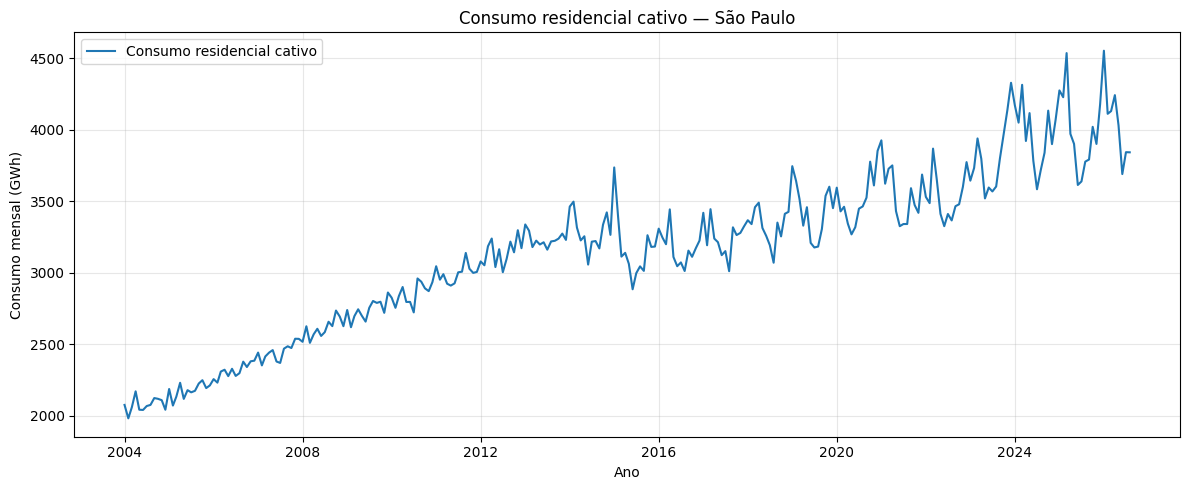

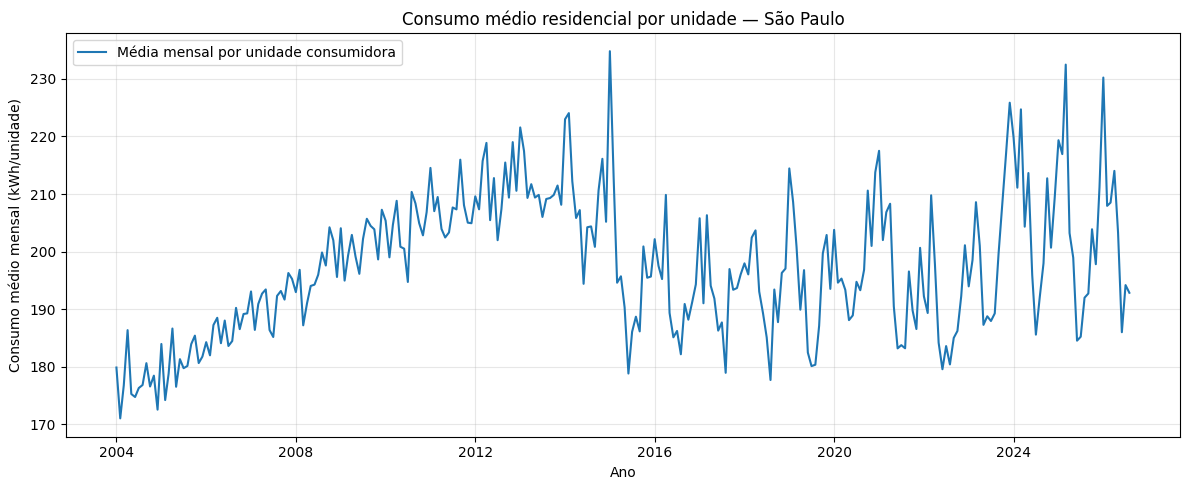

In [117]:
df_graficos = df_epe_processado.copy()
df_graficos["data"] = pd.to_datetime(df_graficos["data"])
df_graficos = df_graficos.sort_values("data")

plt.figure(figsize=(12, 5))
plt.plot(
    df_graficos["data"],
    df_graficos["consumo_cativo_mwh"] / 1000,
    label="Consumo residencial cativo"
)
plt.title("Consumo residencial cativo — São Paulo")
plt.xlabel("Ano")
plt.ylabel("Consumo mensal (GWh)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 5))
plt.plot(
    df_graficos["data"],
    df_graficos["media_cativo_kwh_uc"],
    label="Média mensal por unidade consumidora"
)
plt.title("Consumo médio residencial por unidade — São Paulo")
plt.xlabel("Ano")
plt.ylabel("Consumo médio mensal (kWh/unidade)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### 3.8. Resumo anual e interpretação

O consumo anual é a soma dos meses disponíveis. A média anual por unidade é calculada como consumo acumulado dividido pela soma das unidades consumidoras registradas em cada mês; portanto, é uma média ponderada pelos registros mensais.

Anos incompletos devem ser identificados e não comparados diretamente com anos completos sem ressalva.

In [118]:
df_graficos["ano"] = df_graficos["data"].dt.year

resumo_anual = (
    df_graficos
    .groupby("ano")
    .agg(
        meses_registrados=("data", "nunique"),
        consumo_cativo_gwh=("consumo_cativo_mwh", lambda s: s.sum() / 1000),
        consumo_acumulado_kwh=("consumo_cativo_kwh", "sum"),
        soma_unidades_mes=("unidades_cativo", "sum")
    )
    .reset_index()
)

resumo_anual["media_mensal_kwh_uc"] = (
    resumo_anual["consumo_acumulado_kwh"]
    / resumo_anual["soma_unidades_mes"]
)

resumo_anual = resumo_anual.drop(
    columns=["consumo_acumulado_kwh", "soma_unidades_mes"]
)

print("Resumo anual do consumo residencial cativo:")
display(resumo_anual.round(2))

Resumo anual do consumo residencial cativo:


,ano,meses_registrados,consumo_cativo_gwh,media_mensal_kwh_uc
0,2004,12,"24,893.510",177.090
1,2005,12,"26,123.510",181.070
2,2006,12,"27,772.160",186.440
3,2007,12,"29,349.810",191.390
4,2008,12,"31,300.990",195.940
5,2009,12,"32,871.030",201.560
6,2010,12,"34,214.110",203.940
7,2011,12,"35,917.900",207.470
8,2012,12,"37,680.310",211.140
9,2013,12,"38,782.680",211.070


### 3.9. Interpretação dos resultados da EPE

A série estadual permite observar a evolução do consumo residencial agregado e contextualizar a escala do consumo por unidade consumidora.

Na leitura dos resultados já obtidos:

- O consumo estadual cresceu de forma expressiva entre 2004 e 2025.
- A média por unidade consumidora oscilou ao longo do período e não acompanhou o crescimento agregado na mesma proporção.
- O ano de 2026 possui somente oito meses disponíveis nesta extração.
- Os registros de mercado Livre aparecem a partir de janeiro de 2024 na base examinada; por isso, o total Cativo + Livre não é calculado para os meses anteriores.

Essas observações são descritivas. Elas não demonstram, por si só, as causas das variações.

## 4. Perfil residencial simulado

Será considerada uma família hipotética de quatro moradores em São Paulo — SP. O consumo será estimado a partir da potência dos equipamentos, quantidade e tempo de utilização.

**Os valores desta seção são premissas simuladas e ainda precisam ser refinados com etiquetas de consumo, especificações dos fabricantes ou referências técnicas.** Em particular, a geladeira não deve ser modelada simplesmente como se operasse continuamente na potência nominal: seu consumo real depende do ciclo do compressor e da eficiência do equipamento.

Fórmula simplificada para cargas com tempo de uso definido:

\[
E_{mês}(kWh) =
\frac{P(W) \times q \times h(dia) \times d(mês) \times f}{1000}
\]

Onde `f` é um fator de utilização adotado como premissa. Para equipamentos com consumo variável ou ciclo automático, uma medição ou consumo mensal informado pelo fabricante é preferível à estimativa simplificada.

### 4.1. Equipamentos e premissas iniciais

A tabela a seguir preserva as hipóteses preliminares do estudo. Antes de usar o resultado como linha de base definitiva, revise especialmente geladeira, chuveiro e iluminação.

In [119]:
equipamentos = pd.DataFrame([
    {
        "equipamento": "Geladeira",
        "potencia_w": None,
        "quantidade": 1,
        "horas_dia": None,
        "dias_mes": 30,
        "fator_uso": 1.0,
        "consumo_direto_kwh_mes": 28.0,
        "observacao": "Premissa provisória; preferir consumo mensal da etiqueta."
    },
    {
        "equipamento": "Chuveiro elétrico",
        "potencia_w": 5500,
        "quantidade": 1,
        "horas_dia": 0.5,
        "dias_mes": 30,
        "fator_uso": 1.0,
        "consumo_direto_kwh_mes": None,
        "observacao": "Tempo diário total estimado para a residência."
    },
    {
        "equipamento": "Televisão",
        "potencia_w": 100,
        "quantidade": 1,
        "horas_dia": 5,
        "dias_mes": 30,
        "fator_uso": 1.0,
        "consumo_direto_kwh_mes": None,
        "observacao": "Potência e uso hipotéticos."
    },
    {
        "equipamento": "Lâmpadas LED",
        "potencia_w": 9,
        "quantidade": 6,
        "horas_dia": 5,
        "dias_mes": 30,
        "fator_uso": 1.0,
        "consumo_direto_kwh_mes": None,
        "observacao": "Seis lâmpadas utilizadas cinco horas por dia."
    },
    {
        "equipamento": "Notebook",
        "potencia_w": 60,
        "quantidade": 1,
        "horas_dia": 6,
        "dias_mes": 30,
        "fator_uso": 1.0,
        "consumo_direto_kwh_mes": None,
        "observacao": "Potência e uso hipotéticos."
    },
    {
        "equipamento": "Máquina de lavar",
        "potencia_w": 500,
        "quantidade": 1,
        "horas_dia": 1,
        "dias_mes": 12,
        "fator_uso": 1.0,
        "consumo_direto_kwh_mes": None,
        "observacao": "Doze ciclos mensais de uma hora como aproximação."
    }
])

display(equipamentos)

,equipamento,potencia_w,quantidade,horas_dia,dias_mes,fator_uso,consumo_direto_kwh_mes,observacao
0,Geladeira,NaN,1,NaN,30,1.000,28.000,Premissa provisória; preferir consumo mensal d...
1,Chuveiro elétrico,"5,500.000",1,0.500,30,1.000,NaN,Tempo diário total estimado para a residência.
2,Televisão,100.000,1,5.000,30,1.000,NaN,Potência e uso hipotéticos.
3,Lâmpadas LED,9.000,6,5.000,30,1.000,NaN,Seis lâmpadas utilizadas cinco horas por dia.
4,Notebook,60.000,1,6.000,30,1.000,NaN,Potência e uso hipotéticos.
5,Máquina de lavar,500.000,1,1.000,12,1.000,NaN,Doze ciclos mensais de uma hora como aproximação.


### 4.2. Calcular o consumo estimado

O cálculo abaixo aplica a fórmula simplificada às premissas da tabela. O resultado deve ser interpretado como estimativa inicial, não como medição.

In [120]:
consumo_calculado = (
    equipamentos["potencia_w"]
    * equipamentos["quantidade"]
    * equipamentos["horas_dia"]
    * equipamentos["dias_mes"]
    * equipamentos["fator_uso"]
    / 1000
)

equipamentos["consumo_kwh"] = (
    equipamentos["consumo_direto_kwh_mes"]
    .fillna(consumo_calculado)
)

consumo_total_kwh_mes = equipamentos["consumo_kwh"].sum()

print(f"Consumo mensal estimado: {consumo_total_kwh_mes:.2f} kWh")

display(
    equipamentos[
        ["equipamento", "consumo_kwh", "observacao"]
    ].sort_values("consumo_kwh", ascending=False)
)

Consumo mensal estimado: 150.40 kWh


,equipamento,consumo_kwh,observacao
1,Chuveiro elétrico,82.500,Tempo diário total estimado para a residência.
0,Geladeira,28.000,Premissa provisória; preferir consumo mensal d...
2,Televisão,15.000,Potência e uso hipotéticos.
4,Notebook,10.800,Potência e uso hipotéticos.
3,Lâmpadas LED,8.100,Seis lâmpadas utilizadas cinco horas por dia.
5,Máquina de lavar,6.000,Doze ciclos mensais de uma hora como aproximação.


### 4.3. Visualizar a contribuição dos equipamentos

O gráfico permite identificar quais premissas mais influenciam o consumo estimado. Uma participação elevada indica onde uma revisão de uso, potência ou eficiência pode ter maior efeito no modelo.

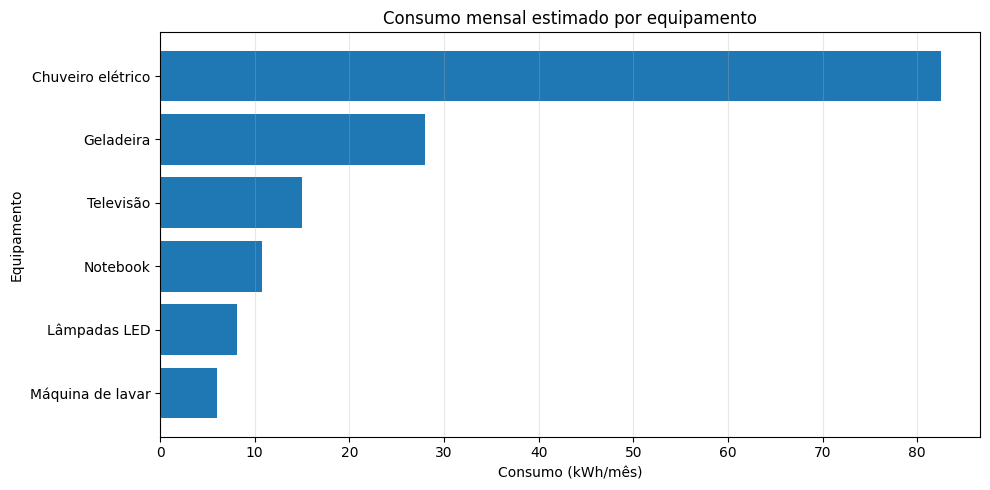

In [121]:
equipamentos_ordenados = equipamentos.sort_values(
    "consumo_kwh", ascending=True
)

plt.figure(figsize=(10, 5))
plt.barh(
    equipamentos_ordenados["equipamento"],
    equipamentos_ordenados["consumo_kwh"]
)
plt.title("Consumo mensal estimado por equipamento")
plt.xlabel("Consumo (kWh/mês)")
plt.ylabel("Equipamento")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### 4.4. Comparar com a referência estadual

A comparação abaixo é apenas contextual. O indicador estadual é uma média por unidade consumidora, enquanto o perfil simulado representa uma residência hipotética com quatro moradores. Diferenças entre os dois valores não indicam automaticamente erro: composição familiar, equipamentos, clima, hábitos e características da unidade podem variar.

In [122]:
ultimo_registro = df_epe_processado.dropna(
    subset=["media_cativo_kwh_uc"]
).sort_values("data").tail(1)

if not ultimo_registro.empty:
    referencia = float(ultimo_registro["media_cativo_kwh_uc"].iloc[0])
    data_referencia = ultimo_registro["data"].iloc[0]

    comparacao = pd.DataFrame([{
        "data_referencia_epe": data_referencia,
        "media_estadual_kwh_uc": referencia,
        "consumo_simulado_kwh_mes": consumo_total_kwh_mes,
        "diferenca_kwh": consumo_total_kwh_mes - referencia,
        "diferenca_percentual": (
            (consumo_total_kwh_mes / referencia - 1) * 100
            if referencia else np.nan
        )
    }])

    display(comparacao.round(2))
else:
    print("Não há média estadual disponível para comparação.")

,data_referencia_epe,media_estadual_kwh_uc,consumo_simulado_kwh_mes,diferenca_kwh,diferenca_percentual
0,2026-08-01,192.830,150.400,-42.430,-22.010


### 4.5. Estimar o custo mensal de energia
O custo de referência é calculado pela multiplicação do consumo mensal estimado pela soma dos componentes tarifários TUSD e TE, obtidos da base de tarifas de aplicação da ANEEL.

O resultado representa uma estimativa simplificada do custo de energia, não o valor final da fatura residencial. Impostos, bandeiras tarifárias, contribuição de iluminação pública e demais componentes não estão incluídos.

In [123]:
custo_estimado_mensal = consumo_total_kwh_mes * tarifa_total_kwh
custo_estimado_anual = custo_estimado_mensal * 12

print(f"Consumo mensal: {consumo_total_kwh_mes:.2f} kWh")
print(f"Tarifa de referência: R$ {tarifa_total_kwh:.5f}/kWh")
print(f"Custo mensal estimado: R$ {custo_estimado_mensal:.2f}")
print(f"Custo anual estimado: R$ {custo_estimado_anual:.2f}")


Consumo mensal: 150.40 kWh
Tarifa de referência: R$ 0.78938/kWh
Custo mensal estimado: R$ 118.72
Custo anual estimado: R$ 1424.67


### 4.6. Exportar o perfil e o resumo
Os arquivos exportados permitem reutilizar os resultados em etapas posteriores do projeto.

In [124]:
ARQUIVO_PERFIL = PROCESSED_DIR / "perfil_residencial_simulado.csv"
ARQUIVO_RESUMO = PROCESSED_DIR / "resumo_consumo.json"

equipamentos.to_csv(
    ARQUIVO_PERFIL,
    index=False,
    encoding="utf-8-sig"
)

resumo = {
    "localidade": LOCALIDADE,
    "distribuidora": DISTRIBUIDORA,
    "moradores": PERFIL_RESIDENCIAL["moradores"],
    "consumo_estimado_kwh_mes": round(float(consumo_total_kwh_mes), 2),
    "origem_perfil": "Simulado",
    "data_execucao": datetime.now().isoformat(timespec="seconds"),
    "tarifa_referencia_kwh": round(float(tarifa_total_kwh), 5),
    "custo_estimado_mensal": round(float(custo_estimado_mensal), 2),
    "observacao": (
        "Estimativa baseada em premissas de potência e utilização; "
        "não representa medição real."
    )
}

with open(ARQUIVO_RESUMO, "w", encoding="utf-8") as arquivo:
    json.dump(resumo, arquivo, ensure_ascii=False, indent=4)

print("Perfil exportado:", ARQUIVO_PERFIL)
print("Resumo exportado:", ARQUIVO_RESUMO)
display(pd.DataFrame([resumo]))

Perfil exportado: /content/GS_SERS/data/processed/perfil_residencial_simulado.csv
Resumo exportado: /content/GS_SERS/data/processed/resumo_consumo.json


,localidade,distribuidora,moradores,consumo_estimado_kwh_mes,origem_perfil,data_execucao,tarifa_referencia_kwh,custo_estimado_mensal,observacao
0,São Paulo - SP,Enel Distribuição São Paulo,4,150.400,Simulado,2026-11-13T02:50:48,0.789,118.720,Estimativa baseada em premissas de potência e ...


## 5. Limitações e próximos passos

### Limitações desta etapa

1. **EPE:** os dados são agregados por UF e classe; não identificam o consumo de uma residência específica.
2. **Cobertura Cativo/Livre:** a série Livre disponível nesta extração começa em janeiro de 2024. O total das duas categorias só é calculado quando há registros de ambas.
3. **ANEEL:** TUSD e TE são componentes tarifários e não representam, isoladamente, o valor final da fatura.
4. **Perfil simulado:** potências e hábitos de uso são premissas iniciais. Devem ser refinados antes de sustentar recomendações quantitativas.
5. **Armazenamento:** no Google Colab, `/content` é temporário. Os arquivos originais e processados devem ser copiados para armazenamento persistente ou versionados no repositório.

### Próximas etapas previstas

Utilizar a linha de base residencial para construir cenários de eficiência energética.

- Obter dados de irradiação solar para São Paulo em fonte oficial.
- Estimar a geração fotovoltaica e o dimensionamento do sistema.
- Comparar alternativas de eficiência energética e geração renovável.
- Avaliar custos, economia, viabilidade e impactos ambientais.

## 6. Verificação dos arquivos gerados

A célula final lista os arquivos presentes no diretório do projeto. Antes de encerrar a sessão do Colab, copie a pasta `GS_SERS` para o Google Drive ou baixe os arquivos necessários.

In [125]:
print("Arquivos disponíveis no projeto:\n")

for arquivo in sorted(BASE_DIR.rglob("*")):
    if arquivo.is_file():
        print(
            arquivo.relative_to(BASE_DIR),
            "-",
            round(arquivo.stat().st_size / 1024, 2),
            "KB"
        )

Arquivos disponíveis no projeto:

data/processed/epe_sp_residencial_mensal.csv - 22.53 KB
data/processed/perfil_residencial_simulado.csv - 0.59 KB
data/processed/resumo_consumo.json - 0.41 KB
data/raw/aneel_tarifas_original.parquet - 2536.62 KB
data/raw/epe_consumo_mensal_original.xlsx - 13597.65 KB
references/fontes.json - 0.89 KB


## 7. Referências

- **ANEEL — Dados Abertos:** https://dadosabertos.aneel.gov.br/
- **EPE — Dados do Consumo Mensal de Energia Elétrica:** https://www.epe.gov.br/pt/publicacoes-dados-abertos/dados-abertos/dados-do-consumo-mensal-de-energia-eletrica
- **EPE — Dicionário de Dados do Consumo Mensal:** https://www.epe.gov.br/sites-pt/publicacoes-dados-abertos/dados-abertos/Documents/Consumo-Mensal-Dicionario-de-Dados.pdf
- **INPE/LABREN — Atlas Brasileiro de Energia Solar:** https://labren.ccst.inpe.br/atlas_2017.html

As datas de acesso, versões dos arquivos e demais metadados devem ser registrados na versão final do relatório, de acordo com os arquivos efetivamente utilizados.